# Exercise for Pandas

## Preface
The goal of this exercise is to get a basic understanding of data operations with `pandas` as an explorative tool of data science. Here we will look at a concrete data set that will serve as a basis for the exercises.

## Scenario: US elections

The presidential elections in the US are held publicly every 4 years (since 1788) under media aspects. The candidates are determined by internal party primaries. The absolute majority of so-called *presidential electors* is taken into account when counting the votes. Thus,  citizens do not directly elect the potential president but members (the presidential electors) of the *Electoral College*  (group consisting of 538 members), with each state having a different number of presidential electors. At the end of an election, the collected votes of the presidential electors are publicly counted by the Senate and the House of Representatives. The potential presidential candidate with the absolute majority is considered elected.

In this exercise notebook, we will examine and analyse in more detail a specific data set on the US presidential election from 1976 - 2016 using `pandas`.

All data sources used for the exercise were generated on the basis of data from [Harvard Dataverse](https://dataverse.harvard.edu/dataverse/medsl_president) through extensive data preparation. The data sets offered on this page are provided by the [MIT Election Data & Science Lab](https://electionlab.mit.edu/) in cooperation with [Harvard University](https://support.dataverse.harvard.edu/) and are available free of charge for educational purposes.

## 0. Import

Import all necessary Python libraries you need to work with datasets. Also make sure that you are able to read from SQLite databases.

In [65]:

import pandas as pd
import sqlite3 as sql
import matplotlib.pyplot as plt

## 1. Read Data from SQLite Database

<h4><span style="color:blue">Complete following tasks:</span></h4>

**1.1**. Read the dataset from the SQLite-Database `data/usa_presidents.db` (table name: `president_table`)

**1.2.** Output the first 5 lines of your Pandas DataFrame.

**Note:**   
* If you want to inspect the SQLite database, [this tool](https://sqlitebrowser.org/dl/) might be helpful.
* If you don't remember certain parts, you can have a look at the MAT notebooks again.

In [66]:
# 1.1 read data from the database usa_presidents.db
sql_connection = sql.connect('data/usa_presidents.db')
data_set = pd.read_sql('SELECT * FROM president_table', sql_connection)
sql_connection.close()

In [67]:
# 1.2 check the first 5 rows
data_set.head()


,year,state,state_po,state_fips,state_cen,state_ic,office,candidate,party,writein,candidatevotes,totalvotes,version,notes
0,1976,Alabama,AL,1,63,41,US President,"Carter, Jimmy",democrat,FALSE,659170,1182850,20171015,NA
1,1976,Alabama,AL,1,63,41,US President,"Ford, Gerald",republican,FALSE,504070,1182850,20171015,NA
2,1976,Alabama,AL,1,63,41,US President,"Maddox, Lester",american independent party,FALSE,9198,1182850,20171015,NA
3,1976,Alabama,AL,1,63,41,US President,"Bubar, Benjamin """"Ben""""",prohibition,FALSE,6669,1182850,20171015,NA
4,1976,Alabama,AL,1,63,41,US President,"Hall, Gus",communist party use,FALSE,1954,1182850,20171015,NA


## 2. Pandas Statistics

### Overview of the data
<h4><span style="color:blue">Complete the following tasks:</span></h4>

**2.1.** Obtain information about the meta information and statistical information of the dataset!

**2.2.** Fetch 5 records starting with the *fifth* one ( *Note*: the position index starts with 0 ) 

In [68]:
# 2.1 get information about the dataframe structure/ meta data
data_set.info()


<class 'pandas.DataFrame'>
RangeIndex: 3740 entries, 0 to 3739
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   year            3740 non-null   int64
 1   state           3740 non-null   str  
 2   state_po        3740 non-null   str  
 3   state_fips      3740 non-null   str  
 4   state_cen       3740 non-null   str  
 5   state_ic        3740 non-null   str  
 6   office          3740 non-null   str  
 7   candidate       3740 non-null   str  
 8   party           3740 non-null   str  
 9   writein         3740 non-null   str  
 10  candidatevotes  3740 non-null   int64
 11  totalvotes      3740 non-null   int64
 12  version         3740 non-null   str  
 13  notes           3740 non-null   str  
dtypes: int64(3), str(11)
memory usage: 409.2 KB


In [69]:
# 2.1 get some basic statistics from the dataframe
data_set.describe()

,year,candidatevotes,totalvotes
count,3740.000000,3.740000e+03,3.740000e+03
mean,1996.021390,3.151389e+05,2.214284e+06
std,12.586011,7.371322e+05,2.252806e+06
min,1976.000000,1.000000e+00,1.235740e+05
25%,1984.000000,1.498750e+03,6.296560e+05
50%,1996.000000,8.992000e+03,1.533950e+06
75%,2008.000000,2.245050e+05,2.808605e+06
max,2016.000000,8.753788e+06,1.418160e+07


In [70]:
# 2.2 return 5 rows starting from the fifth one, better with iloc.
#df_presidents[4:9]
data_set.iloc[4:9]


,year,state,state_po,state_fips,state_cen,state_ic,office,candidate,party,writein,candidatevotes,totalvotes,version,notes
4,1976,Alabama,AL,1,63,41,US President,"Hall, Gus",communist party use,FALSE,1954,1182850,20171015,NA
5,1976,Alabama,AL,1,63,41,US President,"Macbride, Roger",libertarian,FALSE,1481,1182850,20171015,NA
6,1976,Alabama,AL,1,63,41,US President,,,TRUE,308,1182850,20171015,NA
7,1976,Alaska,AK,2,94,81,US President,"Ford, Gerald",republican,FALSE,71555,123574,20171015,NA
8,1976,Alaska,AK,2,94,81,US President,"Carter, Jimmy",democrat,FALSE,44058,123574,20171015,NA


### Some Simple Queries

**2.3** Get all the information about state *Kentucky*.

**2.4** Show the party column (only) for all rows about the state of *California*


In [71]:
# 2.3 obtain all infromation about Kentucky
data_set[data_set.state=="Kentucky"]

,year,state,state_po,state_fips,state_cen,state_ic,office,candidate,party,writein,candidatevotes,totalvotes,version,notes
102,1976,Kentucky,KY,21,61,51,US President,"Carter, Jimmy",democrat,FALSE,615717,1167142,20171015,NA
103,1976,Kentucky,KY,21,61,51,US President,"Ford, Gerald",republican,FALSE,531852,1167142,20171015,NA
104,1976,Kentucky,KY,21,61,51,US President,"Anderson, Thomas J.",american,FALSE,8308,1167142,20171015,NA
105,1976,Kentucky,KY,21,61,51,US President,"McCarthy, Eugene """"Gene""""",independent,FALSE,6837,1167142,20171015,NA
106,1976,Kentucky,KY,21,61,51,US President,"Maddox, Lester",american independent party,FALSE,2328,1167142,20171015,NA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3519,2016,Kentucky,KY,21,61,51,US President,"Johnson, Gary",libertarian,FALSE,53752,1924149,20171015,NA
3520,2016,Kentucky,KY,21,61,51,US President,"McMullin, Evan",independent,FALSE,22780,1924149,20171015,NA
3521,2016,Kentucky,KY,21,61,51,US President,"Stein, Jill",green,FALSE,13913,1924149,20171015,NA
3522,2016,Kentucky,KY,21,61,51,US President,"De La Fuente, Roque """"Rocky""""",american delta party,FALSE,1128,1924149,20171015,NA


In [72]:
# 2.4 Show the *party* column (only) for all rows about the state of *California*
data_set["party"][data_set.state == "California"]

23                      republican
24                        democrat
25                     independent
26      american independent party
27                 peace & freedom
                   ...            
3426                    republican
3427                   libertarian
3428                         green
3429                              
3430               peace & freedom
Name: party, Length: 74, dtype: str

**2.5** Find all rows where candidates had less or equal than $10$ candidate votes (show only the year, state name and the candidate name). Similar to this SQL statement:

```SQL
SELECT year, state, candidate 
FROM president_table
WHERE candidatevotes <= 10
```

In [73]:
# 2.5 find all rows with less or equal to 10 candidate votes
data_set[data_set.candidatevotes <= 10][["year", "state", "candidate"]]

,year,state,candidate
354,1980,Arizona,"Griswold, Deirdre"
893,1984,New Mexico,Other
1056,1988,Connecticut,
1327,1992,Arizona,
1465,1992,Massachusetts,"Dodge, Earl"
1736,1996,Connecticut,
2286,2000,New York,
2362,2000,Utah,
2536,2004,Maine,Blank Vote/Scattering
2544,2004,Maryland,Other


**2.6** Apparently, there are some empty cells in the candidate column (*data consistency* problem). Repeat task **2.5** but this time show only non-empty candidate cells. Similar to this SQL:

```SQL
SELECT year, state, candidate 
FROM president_table
WHERE candidatevotes <= 10 AND candidate != "";
```

In [74]:
# 2.6 logical condition
data_set[(data_set.candidatevotes <= 10) & (data_set.candidate !="")][["year", "state", "candidate"]]

,year,state,candidate
354,1980,Arizona,"Griswold, Deirdre"
893,1984,New Mexico,Other
1465,1992,Massachusetts,"Dodge, Earl"
2536,2004,Maine,Blank Vote/Scattering
2544,2004,Maryland,Other
2634,2004,North Dakota,Other
2715,2004,West Virginia,"Cobb, David"


**2.7** Maybe it is worth inspecting (and fixing) the candidate name. Give the top-10 value counts for candidates (probably the empty string will show up. Find out, if there is already a "replacement" word for missing values

In [75]:
# 2.7 Find out about most used *candidate*s
data_set.candidate.value_counts().head(10)

candidate
                     266
Nader, Ralph         137
Other                106
Bush, George H.W.    105
Reagan, Ronald       104
Clinton, Bill        104
Bush, George W.      104
Obama, Barack H.     104
Carter, Jimmy        103
Perot, Ross           98
Name: count, dtype: int64

**2.8** Probably you found out, that there is a name called "Other". Replace all missing values in the candidate names with "Other". Verify if it worked (if not, find a solution!)

In [76]:
# 2.8 cleanse missing names
data_set["candidate"] = data_set["candidate"].replace("", "Other")
# verify...
data_set.candidate.value_counts().head(10)

candidate
Other                372
Nader, Ralph         137
Bush, George H.W.    105
Reagan, Ronald       104
Clinton, Bill        104
Bush, George W.      104
Obama, Barack H.     104
Carter, Jimmy        103
Perot, Ross           98
Browne, Harry         96
Name: count, dtype: int64

### 3. Pivot Tables and Matplotlib


**3.1** Create a Pivot table showing the candidate names and the sum of their candidatevotes (we ignore the years, just sum over all years)

In [77]:
candidate_votes = pd.pivot_table(data_set, index="candidate", values="candidatevotes", aggfunc="sum")
candidate_votes

,candidatevotes
candidate,
"Alexander, Stewart",4074
"Allen, Jonathan",348
"Amondson, Gene",2597
"Anderson, John B.",5720701
"Anderson, Ross Carl """"Rocky""""",28459
...,...
Workers World,253
"Wright, Margaret",46914
"Yiamouyiannis, John",808


**3.2** Now, create a Pivot table showing summed up votes per state and per year

In [78]:
# 3.2 Pivot table showing summed up votes per state and per year
state_year_votes = pd.pivot_table(data_set, index=['state', 'year'], values="candidatevotes", aggfunc="sum")
state_year_votes

candidatevotes
state   year                
Alabama 1976         1182850
        1980         1341929
        1984         1441713
        1988         1378476
        1992         1688060
...                      ...
Wyoming 2000          213726
        2004          243861
        2008          254904
        2012          250701
        2016          258788

[561 rows x 1 columns]

**3.3** Finally, create a plot(matplotlib)  showing the candidatevotes from *California* and *Kentucky* over the years. Luckily, you can  use the data from the Pivot table in 3.2. Please make sure your plot has a title, a legend and names for the axis.

**Hint**:
> The names of the states are automatically the index of your Pivot table. We have not found out how to use a text as an index yet, only numbers. In order to get the data from the Pivot table, you can use *loc*: `c = df.loc['California']`

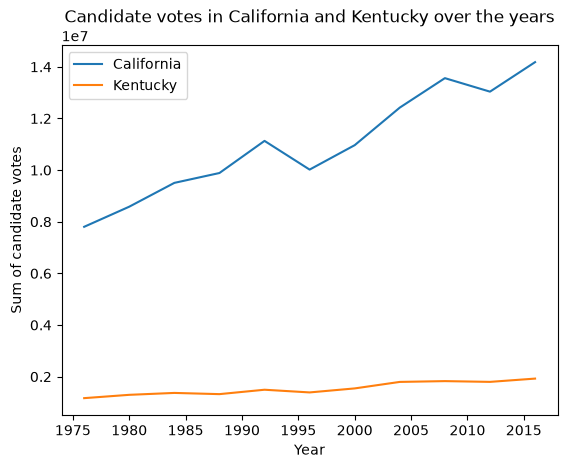

In [79]:
# 3.3. Get the data from the Pivot table
california = state_year_votes.loc['California']
kentucky = state_year_votes.loc["Kentucky"]
# Plot the lines using matplotlib
plt.plot(california.index, california["candidatevotes"])
plt.plot(kentucky.index, kentucky["candidatevotes"])

plt.title("Candidate votes in California and Kentucky over the years")
plt.xlabel("Year")
plt.ylabel("Sum of candidate votes")
plt.legend(['California', 'Kentucky'])
plt.show()